# Task 3: Unemployment Analysis in India

**Intern Infobyte | Data Science Internship | Repository: `INIB`**

---

## 1. Objective
Analyze unemployment trends in India using Python (Pandas, Matplotlib, Seaborn) to **identify patterns and potential causes**, with a special focus on the impact of the **COVID-19 lockdown (2020)**, and to turn the findings into **policy recommendations**.

## 2. Datasets
| File | Rows | Period | Key columns |
|---|---|---|---|
| `Unemployment_in_India.csv` | 740 (after cleaning) | May 2019 to Jun 2020 | Region (state), Date, Unemployment Rate, Employed, Labour Participation Rate, **Area (Rural/Urban)** |
| `Unemployment_Rate_upto_11_2020.csv` | 267 | Jan 2020 to Oct 2020 | Region (state), Date, Unemployment Rate, Employed, Labour Participation Rate, **Zone (North/South/East/West/Northeast)**, latitude, longitude |

> **Note on the task slide:** the slide mentions age, gender, education and industry. These datasets do **not** contain those columns, so the demographic dimensions available here are **Rural vs Urban**, **State**, **Zone** and **Time**. This is stated honestly in the README as a limitation.

## 3. Methodology
1. Load and inspect the data
2. Clean the data (headers, missing rows, dates, duplicate column names, swapped coordinates)
3. Feature engineering (month, COVID phase)
4. Exploratory data analysis and visualization
5. Statistical testing
6. State clustering (KMeans) as a bonus
7. Insights and policy recommendations

## 4. Import Libraries

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"

os.makedirs("images", exist_ok=True)

def save_fig(name):
    """Save the current figure into the images/ folder (used by the README)."""
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")

print("Libraries loaded successfully")

Libraries loaded successfully


## 5. Load the Data

In [2]:
# Load datasets directly from the folder
import os
file1 = "Unemployment in India.csv" if os.path.exists("Unemployment in India.csv") else "data/Unemployment_in_India.csv"
file2 = "Unemployment_Rate_upto_11_2020.csv" if os.path.exists("Unemployment_Rate_upto_11_2020.csv") else "data/Unemployment_Rate_upto_11_2020.csv"

df1_raw = pd.read_csv(file1)
df2_raw = pd.read_csv(file2)

print("Dataset 1 shape:", df1_raw.shape)
print("Dataset 2 shape:", df2_raw.shape)
df1_raw.head()


Dataset 1 shape: (768, 7)
Dataset 2 shape: (267, 9)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [3]:
df2_raw.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,31-03-2020,M,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,30-04-2020,M,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,31-05-2020,M,17.43,12988845,36.46,South,15.9129,79.74


## 6. Data Inspection
Before cleaning, let us look at the structure, data types and missing values.

In [4]:
print("===== DATASET 1 =====")
print("Columns:", list(df1_raw.columns))
print("\nMissing values per column:")
print(df1_raw.isna().sum())
print("\nFully empty rows:", df1_raw.isna().all(axis=1).sum())
print("Duplicate rows (these are just the empty rows repeated):", df1_raw.duplicated().sum())

===== DATASET 1 =====
Columns: ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Missing values per column:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

Fully empty rows: 28
Duplicate rows (these are just the empty rows repeated): 27


In [5]:
print("===== DATASET 2 =====")
print("Columns:", list(df2_raw.columns))
print("\nMissing values per column:")
print(df2_raw.isna().sum())
print("Duplicate rows:", df2_raw.duplicated().sum())

===== DATASET 2 =====
Columns: ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']

Missing values per column:
Region                                      0
 Date                                       0
 Frequency                                  0
 Estimated Unemployment Rate (%)            0
 Estimated Employed                         0
 Estimated Labour Participation Rate (%)    0
Region.1                                    0
longitude                                   0
latitude                                    0
dtype: int64
Duplicate rows: 0


**Problems found**
- Column names have **leading spaces** (e.g. `" Date"`).
- Dataset 1 has **28 completely empty rows**.
- Dataset 2 has a **duplicated column name** (`Region` appears twice: state and zone).
- Dataset 2's `longitude` and `latitude` columns are **swapped** (for example Delhi is stored as longitude 28.70 and latitude 77.10, while Delhi is really at latitude 28.70 and longitude 77.10).
- `Date` is stored as text in `dd-mm-yyyy` format.
- `Frequency` has inconsistent values (`Monthly` vs `M`).

## 7. Data Cleaning

In [6]:
# ---------- Dataset 1 ----------
df1 = df1_raw.copy()
df1.columns = df1.columns.str.strip()
df1 = df1.rename(columns={
    "Estimated Unemployment Rate (%)": "Unemployment_Rate",
    "Estimated Employed": "Employed",
    "Estimated Labour Participation Rate (%)": "Labour_Participation_Rate",
})
df1 = df1.dropna(how="all").reset_index(drop=True)          # remove empty rows

for col in ["Region", "Date", "Frequency", "Area"]:
    df1[col] = df1[col].astype(str).str.strip()             # remove stray spaces

df1["Date"] = pd.to_datetime(df1["Date"], format="%d-%m-%Y")
df1["Frequency"] = "Monthly"

print("Dataset 1 cleaned:", df1.shape)
print("Remaining missing values:", int(df1.isna().sum().sum()))
print("Remaining duplicate rows:", int(df1.duplicated().sum()))
df1.head()

Dataset 1 cleaned: (740, 7)
Remaining missing values: 0
Remaining duplicate rows: 0


,Region,Date,Frequency,Unemployment_Rate,Employed,Labour_Participation_Rate,Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


In [7]:
# ---------- Dataset 2 ----------
df2 = df2_raw.copy()

# The header has two columns called "Region" and swapped coordinate names, so rename by position.
# Original order: ..., Region (zone), longitude (actually LATITUDE values), latitude (actually LONGITUDE values)
df2.columns = ["Region", "Date", "Frequency", "Unemployment_Rate", "Employed",
               "Labour_Participation_Rate", "Zone", "Latitude", "Longitude"]

df2["Region"] = df2["Region"].str.strip()
df2["Zone"] = df2["Zone"].str.strip()
df2["Date"] = pd.to_datetime(df2["Date"].str.strip(), format="%d-%m-%Y")
df2["Frequency"] = "Monthly"

print("Dataset 2 cleaned:", df2.shape)
print("Check Delhi coordinates (should be about 28.7 N, 77.1 E):")
print(df2.loc[df2.Region == "Delhi", ["Latitude", "Longitude"]].iloc[0].to_dict())
df2.head()

Dataset 2 cleaned: (267, 9)
Check Delhi coordinates (should be about 28.7 N, 77.1 E):
{'Latitude': 28.7041, 'Longitude': 77.1025}


,Region,Date,Frequency,Unemployment_Rate,Employed,Labour_Participation_Rate,Zone,Latitude,Longitude
0,Andhra Pradesh,2020-01-31,Monthly,5.48,16635535,41.02,South,15.9129,79.74
1,Andhra Pradesh,2020-02-29,Monthly,5.83,16545652,40.90,South,15.9129,79.74
2,Andhra Pradesh,2020-03-31,Monthly,5.79,15881197,39.18,South,15.9129,79.74
3,Andhra Pradesh,2020-04-30,Monthly,20.51,11336911,33.10,South,15.9129,79.74
4,Andhra Pradesh,2020-05-31,Monthly,17.43,12988845,36.46,South,15.9129,79.74


## 8. Feature Engineering
We add month and year columns and a **COVID phase** label. The phases are an assumption based on the timeline of the Indian lockdown:

- **Pre-COVID:** up to February 2020
- **Lockdown:** March to May 2020 (the national lockdown began on 25 March 2020)
- **Unlock:** June 2020 onward

In [8]:
def get_phase(date):
    if date < pd.Timestamp("2020-03-01"):
        return "Pre-COVID"
    elif date < pd.Timestamp("2020-06-01"):
        return "Lockdown"
    return "Unlock"

phase_order = ["Pre-COVID", "Lockdown", "Unlock"]

for d in (df1, df2):
    d["Year"] = d["Date"].dt.year
    d["Month"] = d["Date"].dt.month
    d["Month_Label"] = d["Date"].dt.strftime("%b-%y")
    d["Phase"] = pd.Categorical(d["Date"].apply(get_phase), categories=phase_order, ordered=True)

print(df1["Phase"].value_counts().sort_index())
print()
print(df2["Phase"].value_counts().sort_index())

Phase
Pre-COVID    536
Lockdown     154
Unlock        50
Name: count, dtype: int64

Phase
Pre-COVID     52
Lockdown      80
Unlock       135
Name: count, dtype: int64


## 9. Descriptive Statistics

In [9]:
num_cols = ["Unemployment_Rate", "Employed", "Labour_Participation_Rate"]
print("Dataset 1 (May 2019 - Jun 2020)")
display(df1[num_cols].describe().round(2))
print("Dataset 2 (Jan 2020 - Oct 2020)")
display(df2[num_cols].describe().round(2))

Dataset 1 (May 2019 - Jun 2020)


,Unemployment_Rate,Employed,Labour_Participation_Rate
count,740.00,740.00,740.00
mean,11.79,7204460.03,42.63
std,10.72,8087988.43,8.11
min,0.00,49420.00,13.33
25%,4.66,1190404.50,38.06
50%,8.35,4744178.50,41.16
75%,15.89,11275489.50,45.50
max,76.74,45777509.00,72.57


Dataset 2 (Jan 2020 - Oct 2020)


,Unemployment_Rate,Employed,Labour_Participation_Rate
count,267.00,267.00,267.00
mean,12.24,13962105.72,41.68
std,10.80,13366318.36,7.85
min,0.50,117542.00,16.77
25%,4.84,2838930.50,37.26
50%,9.65,9732417.00,40.39
75%,16.76,21878686.00,44.06
max,75.85,59433759.00,69.69


In [10]:
print("States in dataset 1:", df1["Region"].nunique())
print("States in dataset 2:", df2["Region"].nunique())
print("Dataset 1 periods:", df1["Date"].min().date(), "to", df1["Date"].max().date())
print("Dataset 2 periods:", df2["Date"].min().date(), "to", df2["Date"].max().date())

print("\nUnemployment rate: highest and lowest single records (dataset 1)")
display(df1.nlargest(5, "Unemployment_Rate")[["Region", "Date", "Area", "Unemployment_Rate"]])
display(df1.nsmallest(5, "Unemployment_Rate")[["Region", "Date", "Area", "Unemployment_Rate"]])

States in dataset 1: 28
States in dataset 2: 27
Dataset 1 periods: 2019-05-31 to 2020-06-30
Dataset 2 periods: 2020-01-31 to 2020-10-31

Unemployment rate: highest and lowest single records (dataset 1)


,Region,Date,Area,Unemployment_Rate
613,Puducherry,2020-04-30,Urban,76.74
614,Puducherry,2020-05-31,Urban,75.00
242,Puducherry,2020-04-30,Rural,74.51
517,Jharkhand,2020-05-31,Urban,70.17
516,Jharkhand,2020-04-30,Urban,61.48


,Region,Date,Area,Unemployment_Rate
25,Assam,2020-06-30,Rural,0.0
51,Chhattisgarh,2020-04-30,Rural,0.0
77,Goa,2020-02-29,Rural,0.0
231,Puducherry,2019-05-31,Rural,0.0
232,Puducherry,2019-06-30,Rural,0.0


---
# PART A: Dataset 1 (May 2019 to Jun 2020): Rural vs Urban and State Analysis

### A1. Distribution of the unemployment rate

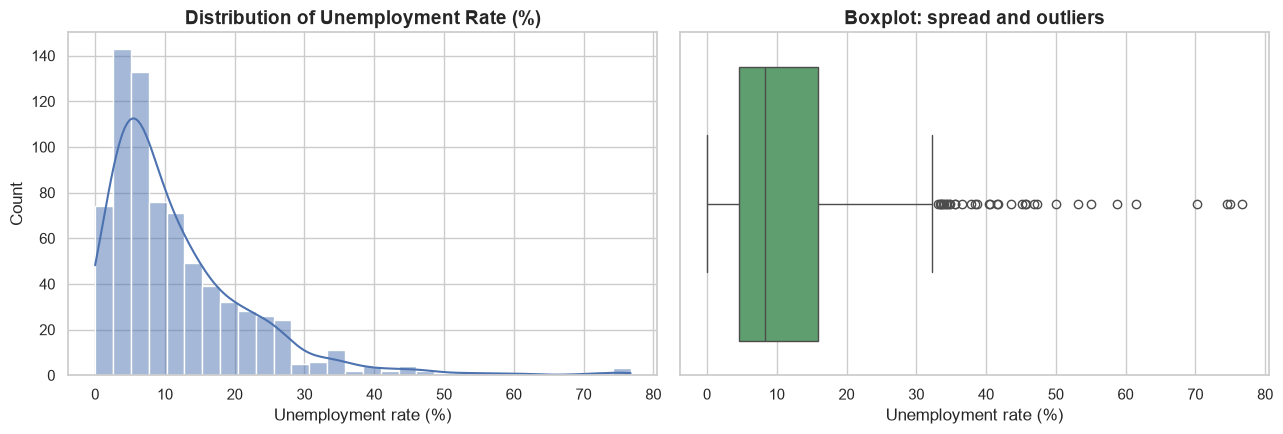

Skewness: 2.22


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df1["Unemployment_Rate"], bins=30, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribution of Unemployment Rate (%)")
axes[0].set_xlabel("Unemployment rate (%)")

sns.boxplot(x=df1["Unemployment_Rate"], ax=axes[1], color="#55A868")
axes[1].set_title("Boxplot: spread and outliers")
axes[1].set_xlabel("Unemployment rate (%)")
plt.tight_layout()
save_fig("01_distribution")
plt.show()

print("Skewness:", round(df1["Unemployment_Rate"].skew(), 2))

The distribution is **right-skewed**: most state-months sit below 10%, but a long tail of extreme values appears, which will turn out to be the lockdown months.

### A2. National trend over time (average across states)

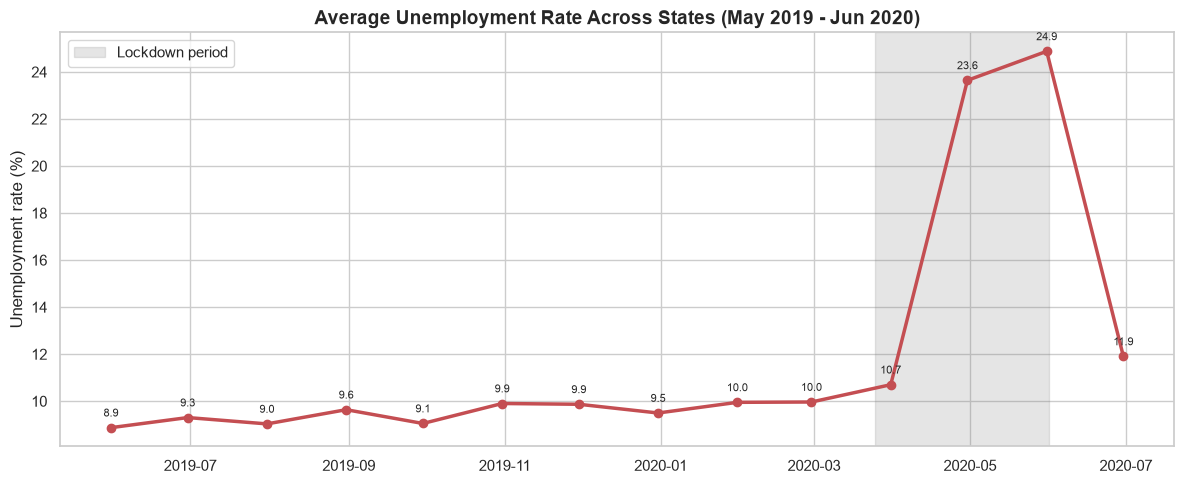

Before lockdown (May 2019 - Feb 2020) average: 9.51 %
Peak month: May 2020 -> 24.88 %


In [12]:
nat = df1.groupby("Date")["Unemployment_Rate"].mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(nat.index, nat.values, marker="o", linewidth=2.5, color="#C44E52")
ax.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-06-01"), color="grey", alpha=0.2, label="Lockdown period")
for x, y in nat.items():
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.set_title("Average Unemployment Rate Across States (May 2019 - Jun 2020)")
ax.set_ylabel("Unemployment rate (%)")
ax.set_xlabel("")
ax.legend()
plt.tight_layout()
save_fig("02_national_trend")
plt.show()

print("Before lockdown (May 2019 - Feb 2020) average:", round(nat[nat.index < "2020-03-01"].mean(), 2), "%")
print("Peak month:", nat.idxmax().strftime("%B %Y"), "->", round(nat.max(), 2), "%")

### A3. Rural vs Urban

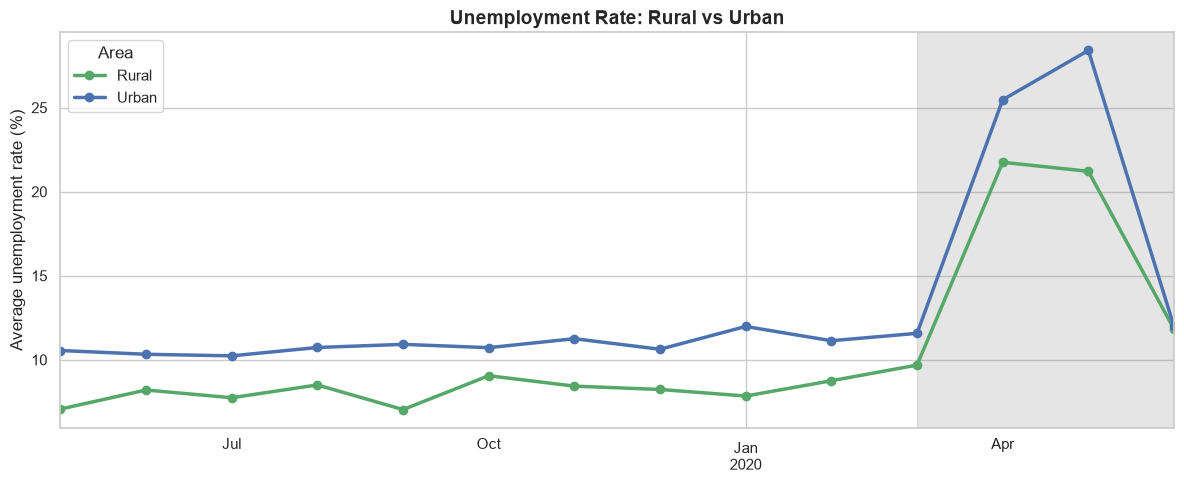

,Unemployment_Rate,Employed,Labour_Participation_Rate
Area,,,
Rural,10.32,10192852.57,44.46
Urban,13.17,4388625.58,40.90


In [13]:
area_trend = df1.groupby(["Date", "Area"])["Unemployment_Rate"].mean().unstack()

fig, ax = plt.subplots(figsize=(12, 5))
area_trend.plot(ax=ax, marker="o", linewidth=2.5, color={"Rural": "#55A868", "Urban": "#4C72B0"})
ax.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-06-01"), color="grey", alpha=0.2)
ax.set_title("Unemployment Rate: Rural vs Urban")
ax.set_ylabel("Average unemployment rate (%)")
ax.set_xlabel("")
plt.tight_layout()
save_fig("03_rural_vs_urban_trend")
plt.show()

display(df1.groupby("Area")[num_cols].mean().round(2))

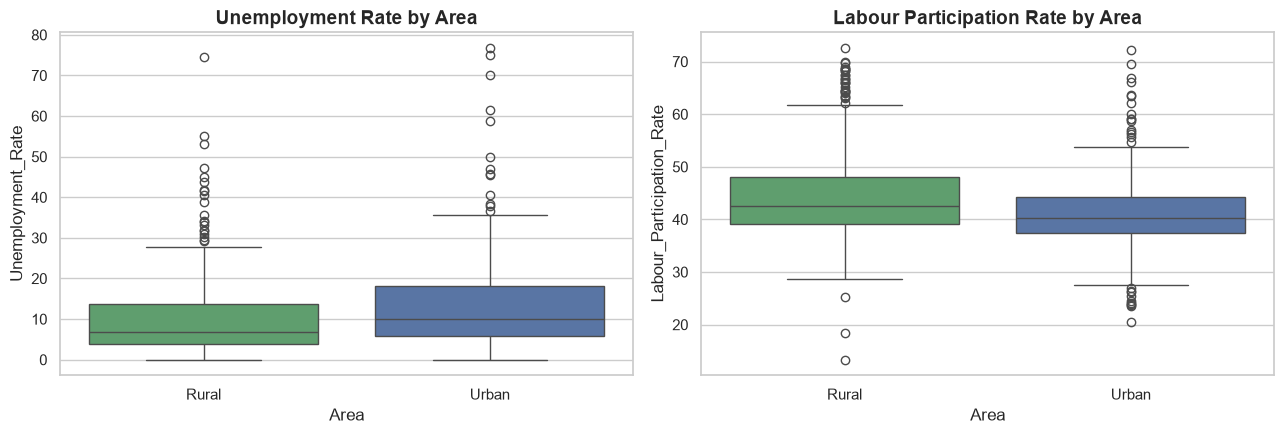

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df1, x="Area", y="Unemployment_Rate", palette=["#55A868", "#4C72B0"], ax=axes[0])
axes[0].set_title("Unemployment Rate by Area")
sns.boxplot(data=df1, x="Area", y="Labour_Participation_Rate", palette=["#55A868", "#4C72B0"], ax=axes[1])
axes[1].set_title("Labour Participation Rate by Area")
plt.tight_layout()
save_fig("04_rural_vs_urban_box")
plt.show()

**Statistical test:** is the Rural vs Urban difference real or just noise?
We use Welch's t-test (does not assume equal variances) and the Mann-Whitney U test (does not assume normality).

In [15]:
rural = df1.loc[df1.Area == "Rural", "Unemployment_Rate"]
urban = df1.loc[df1.Area == "Urban", "Unemployment_Rate"]

t_stat, p_t = stats.ttest_ind(urban, rural, equal_var=False)
u_stat, p_u = stats.mannwhitneyu(urban, rural, alternative="two-sided")

print(f"Mean rural: {rural.mean():.2f}%   Mean urban: {urban.mean():.2f}%")
print(f"Welch t-test:  t = {t_stat:.2f}, p = {p_t:.4f}")
print(f"Mann-Whitney:  U = {u_stat:.0f}, p = {p_u:.4f}")
print("Significant at 5%?", "YES" if p_t < 0.05 else "NO")

Mean rural: 10.32%   Mean urban: 13.17%
Welch t-test:  t = 3.64, p = 0.0003
Mann-Whitney:  U = 82699, p = 0.0000
Significant at 5%? YES


### A4. State-wise analysis

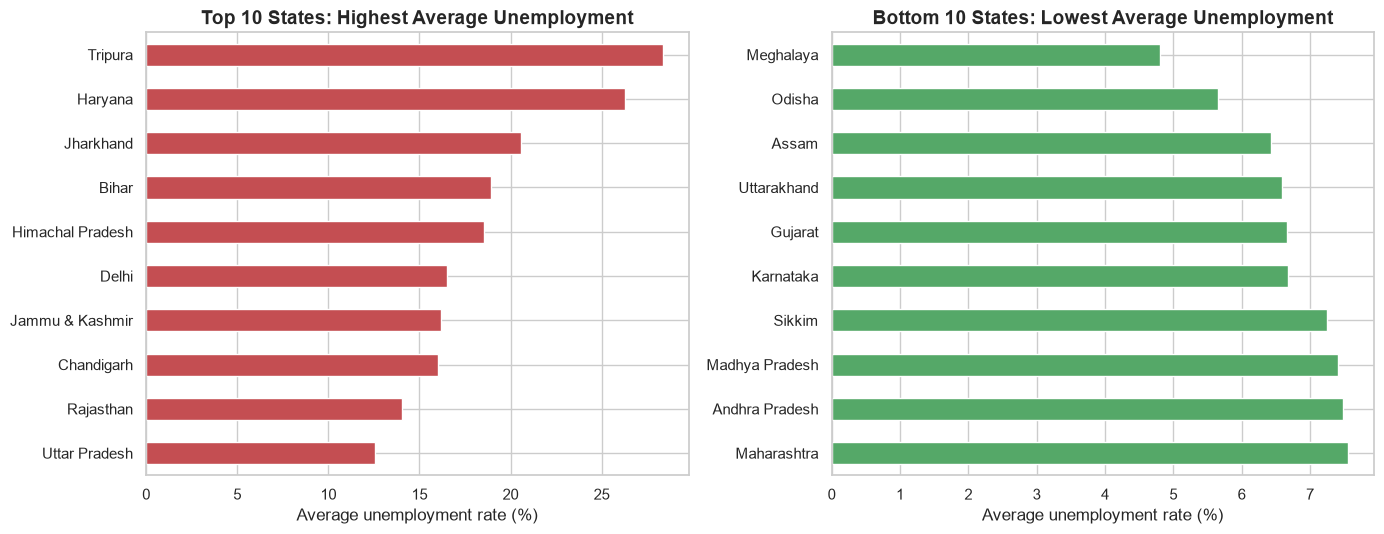

Region
Tripura             28.35
Haryana             26.28
Jharkhand           20.58
Bihar               18.92
Himachal Pradesh    18.54
Delhi               16.50
Jammu & Kashmir     16.19
Chandigarh          15.99
Rajasthan           14.06
Uttar Pradesh       12.55
Name: Unemployment_Rate, dtype: float64


In [16]:
state_avg = df1.groupby("Region")["Unemployment_Rate"].mean().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
state_avg.head(10).sort_values().plot.barh(ax=axes[0], color="#C44E52")
axes[0].set_title("Top 10 States: Highest Average Unemployment")
axes[0].set_xlabel("Average unemployment rate (%)")
axes[0].set_ylabel("")

state_avg.tail(10).sort_values(ascending=False).plot.barh(ax=axes[1], color="#55A868")
axes[1].set_title("Bottom 10 States: Lowest Average Unemployment")
axes[1].set_xlabel("Average unemployment rate (%)")
axes[1].set_ylabel("")
plt.tight_layout()
save_fig("05_state_ranking")
plt.show()

print(state_avg.round(2).head(10))

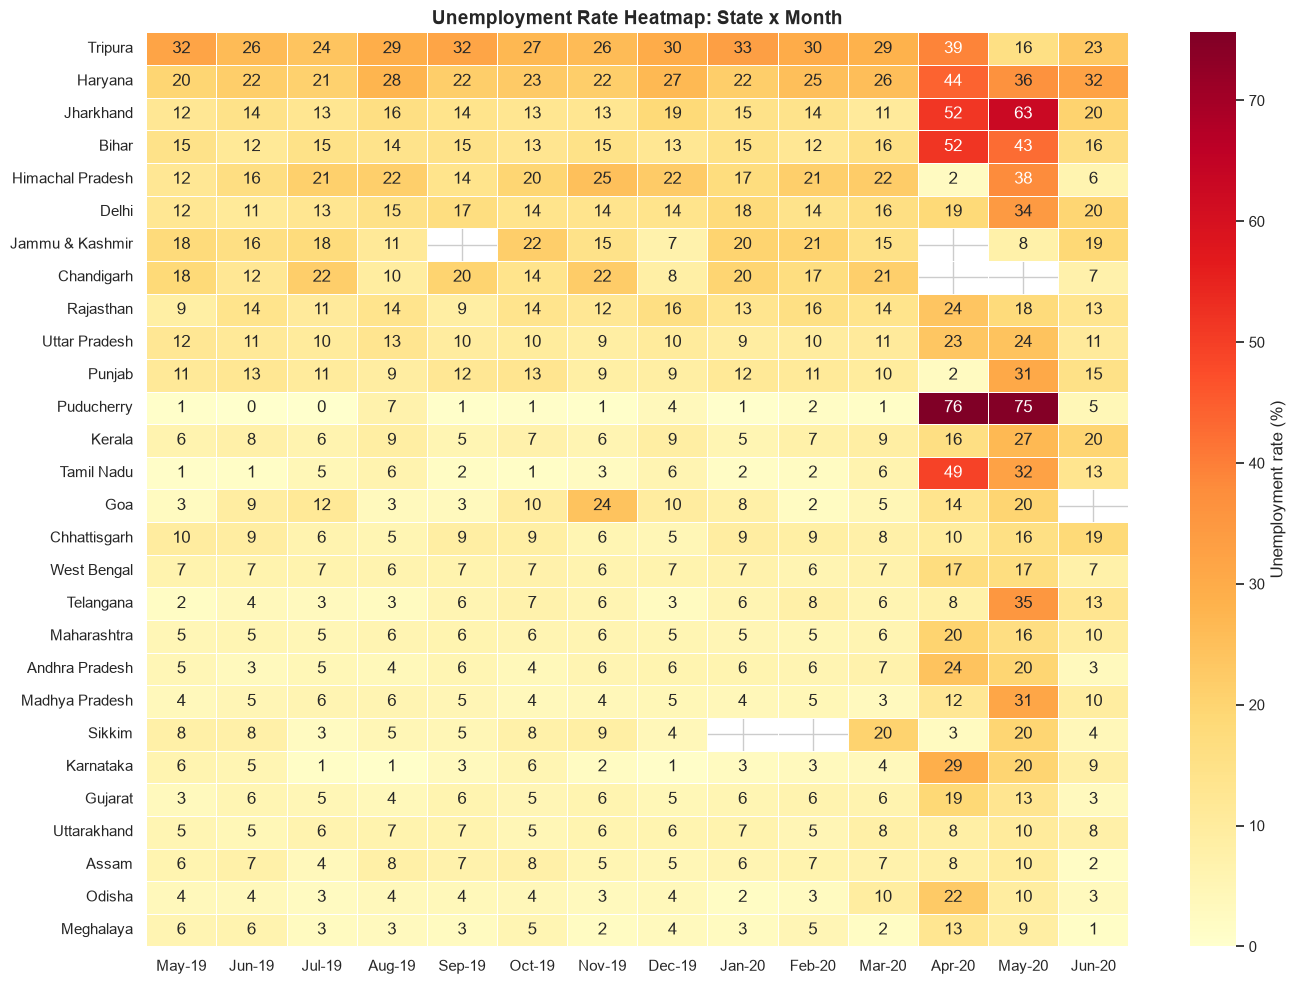

In [17]:
heat = df1.pivot_table(index="Region", columns="Date", values="Unemployment_Rate", aggfunc="mean")
heat.columns = [c.strftime("%b-%y") for c in heat.columns]
heat = heat.loc[state_avg.index]                      # order states by average rate

plt.figure(figsize=(14, 10))
sns.heatmap(heat, cmap="YlOrRd", annot=True, fmt=".0f", linewidths=0.4, cbar_kws={"label": "Unemployment rate (%)"})
plt.title("Unemployment Rate Heatmap: State x Month")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
save_fig("06_state_month_heatmap")
plt.show()

### A5. Impact of the COVID-19 lockdown (state level)

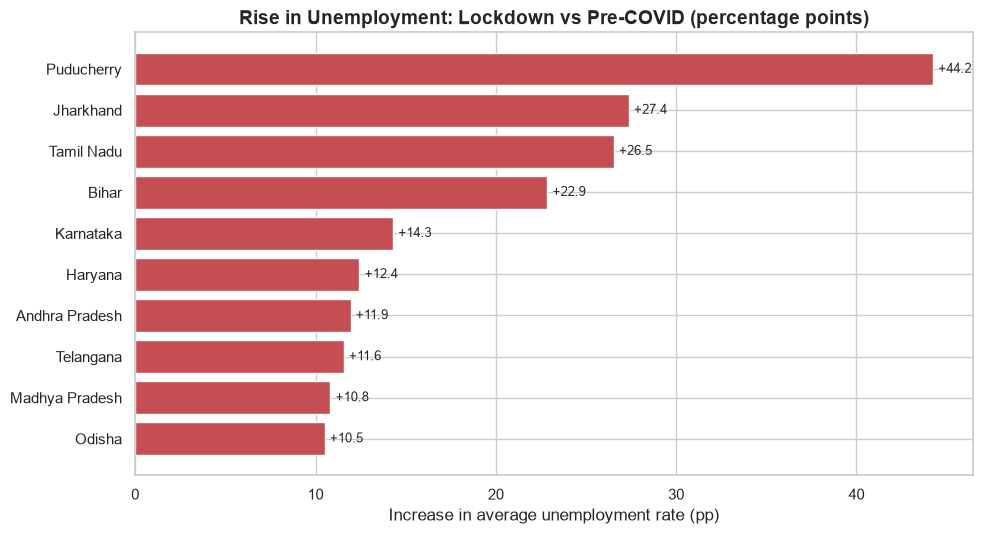

Phase,Pre-COVID,Lockdown,Unlock,Change_pp
Region,,,,
Puducherry,1.59,45.84,4.55,44.24
Jharkhand,14.28,41.65,20.45,27.37
Tamil Nadu,2.84,29.37,13.50,26.54
Bihar,13.83,36.68,16.47,22.85
Karnataka,3.23,17.53,8.52,14.30
Haryana,22.94,35.37,32.49,12.44
Andhra Pradesh,5.04,16.98,3.36,11.95
Telangana,4.66,16.22,13.11,11.56
Madhya Pradesh,4.74,15.56,9.59,10.82


In [18]:
state_phase = df1.pivot_table(index="Region", columns="Phase", values="Unemployment_Rate", aggfunc="mean")
state_phase["Change_pp"] = state_phase["Lockdown"] - state_phase["Pre-COVID"]
state_phase = state_phase.dropna(subset=["Change_pp"]).sort_values("Change_pp", ascending=False)

top = state_phase.head(10).sort_values("Change_pp")
plt.figure(figsize=(10, 5.5))
plt.barh(top.index, top["Change_pp"], color="#C44E52")
for i, v in enumerate(top["Change_pp"]):
    plt.text(v + 0.3, i, f"+{v:.1f}", va="center", fontsize=9)
plt.title("Rise in Unemployment: Lockdown vs Pre-COVID (percentage points)")
plt.xlabel("Increase in average unemployment rate (pp)")
plt.tight_layout()
save_fig("07_covid_impact_states")
plt.show()

display(state_phase.round(2).head(10))

Area,Rural,Urban
Phase,,
Pre-COVID,8.09,10.84
Lockdown,17.65,21.56
Unlock,11.83,11.98


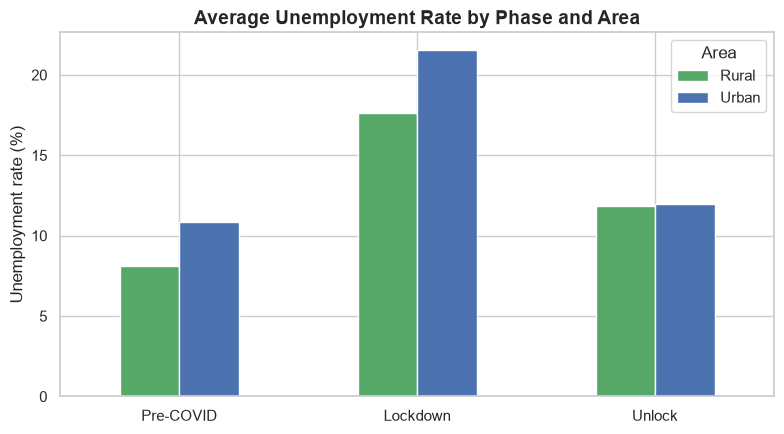

In [19]:
phase_area = df1.groupby(["Phase", "Area"])["Unemployment_Rate"].mean().unstack().round(2)
display(phase_area)

phase_area.plot(kind="bar", figsize=(8, 4.5), color=["#55A868", "#4C72B0"], rot=0)
plt.title("Average Unemployment Rate by Phase and Area")
plt.ylabel("Unemployment rate (%)")
plt.xlabel("")
plt.tight_layout()
save_fig("08_phase_area")
plt.show()

### A6. Relationships between the indicators

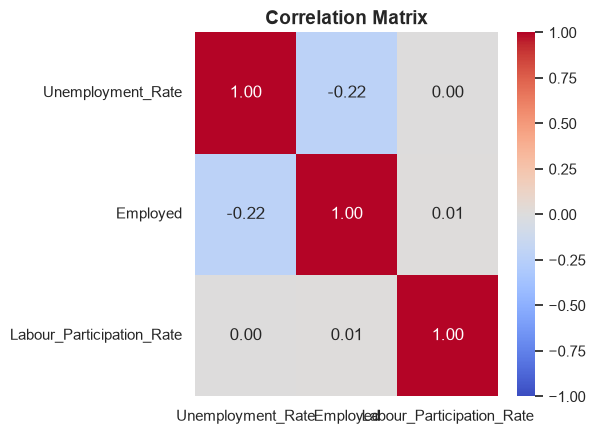

Pearson correlation (participation vs unemployment): r = 0.003, p = 0.9446


In [20]:
corr = df1[num_cols].corr()
plt.figure(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
save_fig("09_correlation")
plt.show()

r, p = stats.pearsonr(df1["Labour_Participation_Rate"], df1["Unemployment_Rate"])
print(f"Pearson correlation (participation vs unemployment): r = {r:.3f}, p = {p:.4f}")

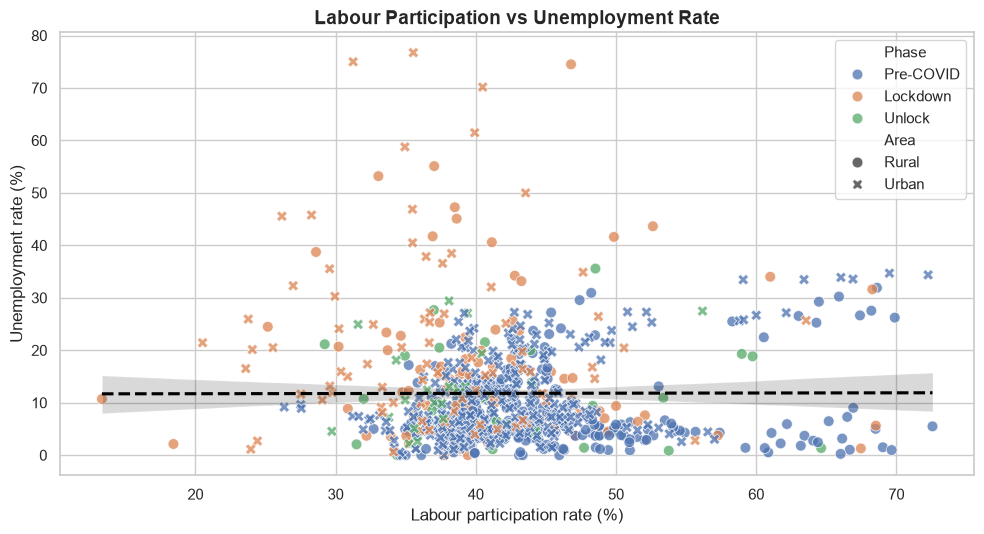

In [21]:
plt.figure(figsize=(10, 5.5))
sns.scatterplot(data=df1, x="Labour_Participation_Rate", y="Unemployment_Rate", hue="Phase", style="Area", alpha=0.75, s=60)
sns.regplot(data=df1, x="Labour_Participation_Rate", y="Unemployment_Rate", scatter=False, color="black", line_kws={"linestyle": "--"})
plt.title("Labour Participation vs Unemployment Rate")
plt.xlabel("Labour participation rate (%)")
plt.ylabel("Unemployment rate (%)")
plt.tight_layout()
save_fig("10_participation_vs_unemployment")
plt.show()

---
# PART B: Dataset 2 (Jan 2020 to Oct 2020): Zones, Recovery and Geography
This dataset extends to October 2020, so it lets us see not only the crash but also the **recovery**.

### B1. National trend through the lockdown and recovery

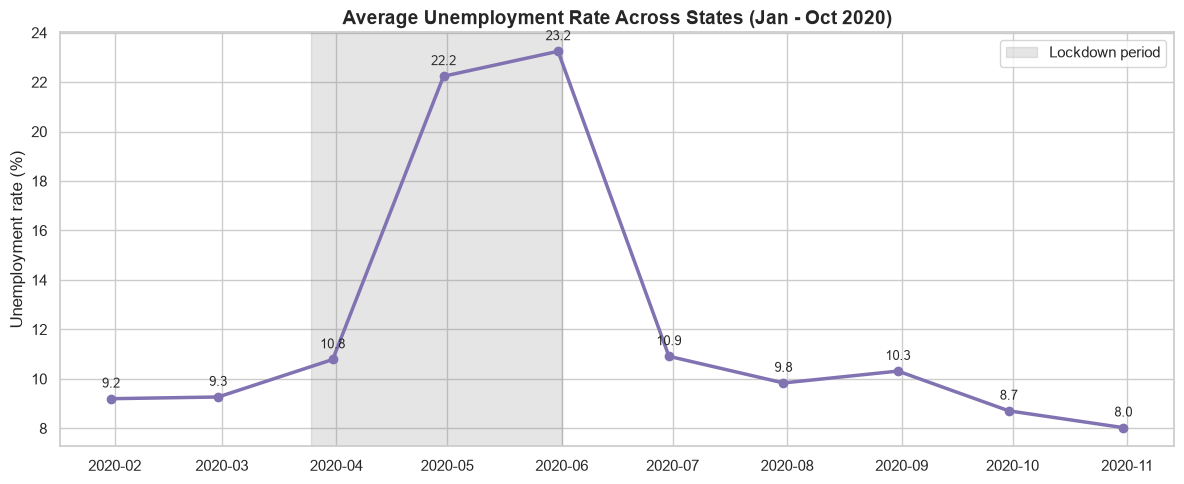

Peak: May 2020 -> 23.24 %
Latest (Oct 2020): 8.03 %
Pre-COVID (Jan-Feb 2020) average: 9.23 %


In [22]:
nat2 = df2.groupby("Date")["Unemployment_Rate"].mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(nat2.index, nat2.values, marker="o", linewidth=2.5, color="#8172B2")
ax.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-06-01"), color="grey", alpha=0.2, label="Lockdown period")
for x, y in nat2.items():
    ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set_title("Average Unemployment Rate Across States (Jan - Oct 2020)")
ax.set_ylabel("Unemployment rate (%)")
ax.set_xlabel("")
ax.legend()
plt.tight_layout()
save_fig("11_trend_2020_recovery")
plt.show()

print("Peak:", nat2.idxmax().strftime("%B %Y"), "->", round(nat2.max(), 2), "%")
print("Latest (Oct 2020):", round(nat2.iloc[-1], 2), "%")
print("Pre-COVID (Jan-Feb 2020) average:", round(nat2.iloc[:2].mean(), 2), "%")

### B2. Zone-wise analysis

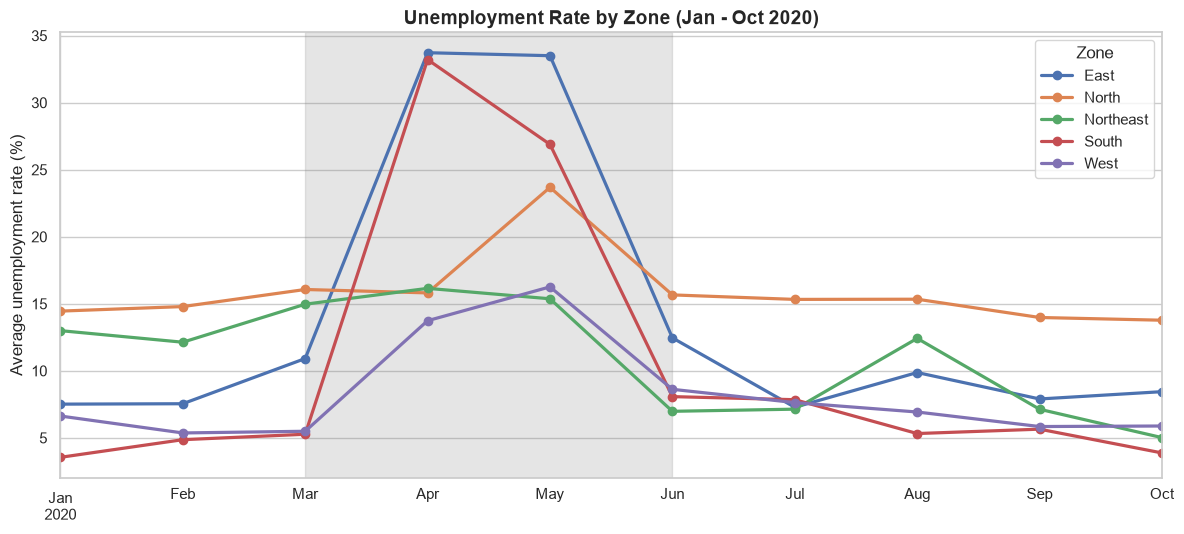

In [23]:
zone_trend = df2.groupby(["Date", "Zone"])["Unemployment_Rate"].mean().unstack()

fig, ax = plt.subplots(figsize=(12, 5.5))
zone_trend.plot(ax=ax, marker="o", linewidth=2.3)
ax.axvspan(pd.Timestamp("2020-03-25"), pd.Timestamp("2020-06-01"), color="grey", alpha=0.2)
ax.set_title("Unemployment Rate by Zone (Jan - Oct 2020)")
ax.set_ylabel("Average unemployment rate (%)")
ax.set_xlabel("")
ax.legend(title="Zone")
plt.tight_layout()
save_fig("12_zone_trend")
plt.show()

Phase,Pre-COVID,Lockdown,Unlock,Lockdown_rise_pp
Zone,,,,
East,7.53,26.05,9.19,18.52
South,4.21,21.79,6.15,17.58
West,6.00,11.83,6.98,5.83
North,14.62,18.64,14.82,4.02
Northeast,12.56,15.50,7.74,2.94


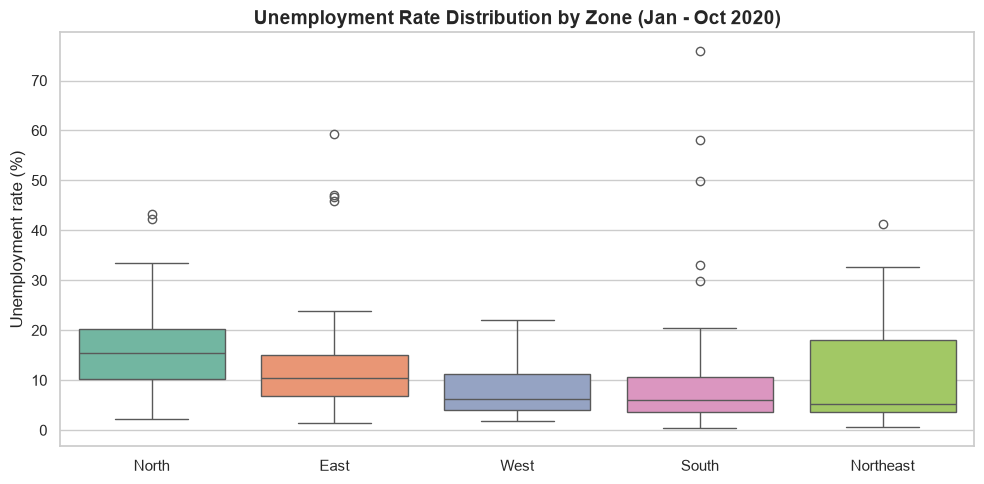

In [24]:
zone_phase = df2.groupby(["Zone", "Phase"])["Unemployment_Rate"].mean().unstack().round(2)
zone_phase["Lockdown_rise_pp"] = (zone_phase["Lockdown"] - zone_phase["Pre-COVID"]).round(2)
display(zone_phase.sort_values("Lockdown_rise_pp", ascending=False))

plt.figure(figsize=(10, 5))
order = df2.groupby("Zone")["Unemployment_Rate"].median().sort_values(ascending=False).index
sns.boxplot(data=df2, x="Zone", y="Unemployment_Rate", order=order, palette="Set2")
plt.title("Unemployment Rate Distribution by Zone (Jan - Oct 2020)")
plt.ylabel("Unemployment rate (%)")
plt.xlabel("")
plt.tight_layout()
save_fig("13_zone_box")
plt.show()

Do the zones really differ? We test with a one-way ANOVA and the non-parametric Kruskal-Wallis test.

In [25]:
groups = [g["Unemployment_Rate"].values for _, g in df2.groupby("Zone")]
f_stat, p_anova = stats.f_oneway(*groups)
h_stat, p_kw = stats.kruskal(*groups)
print(f"ANOVA:          F = {f_stat:.2f}, p = {p_anova:.4f}")
print(f"Kruskal-Wallis: H = {h_stat:.2f}, p = {p_kw:.4f}")
print("Zones differ significantly at 5%?", "YES" if p_kw < 0.05 else "NO")

ANOVA:          F = 5.04, p = 0.0006
Kruskal-Wallis: H = 43.97, p = 0.0000
Zones differ significantly at 5%? YES


### B3. Which states recovered and which did not?

In [26]:
piv = df2.pivot_table(index="Region", columns="Date", values="Unemployment_Rate")
pre = piv.loc[:, piv.columns < "2020-03-01"].mean(axis=1)
peak = piv.max(axis=1)
peak_month = piv.idxmax(axis=1).dt.strftime("%b")
latest = piv.iloc[:, -1]

rec = pd.DataFrame({"Pre_COVID": pre, "Peak": peak, "Peak_Month": peak_month, "Oct_2020": latest}).dropna()
rec["Recovered_pp"] = rec["Peak"] - rec["Oct_2020"]
rec["Gap_vs_PreCOVID_pp"] = rec["Oct_2020"] - rec["Pre_COVID"]
rec = rec.sort_values("Gap_vs_PreCOVID_pp")
display(rec.round(2))

,Pre_COVID,Peak,Peak_Month,Oct_2020,Recovered_pp,Gap_vs_PreCOVID_pp
Region,,,,,,
Tripura,30.54,41.23,Apr,11.57,29.66,-18.96
Delhi,18.54,42.27,May,6.27,36.00,-12.26
Jammu & Kashmir,20.93,21.08,Jan,16.14,4.94,-4.79
Uttar Pradesh,8.28,21.54,Apr,3.75,17.79,-4.53
Telangana,6.89,14.70,May,2.86,11.84,-4.03
Himachal Pradesh,16.84,26.95,May,13.46,13.49,-3.38
Kerala,6.46,17.88,May,3.88,14.00,-2.58
Chhattisgarh,9.02,14.23,Jun,6.62,7.61,-2.40
Gujarat,5.96,18.71,Apr,4.03,14.68,-1.93


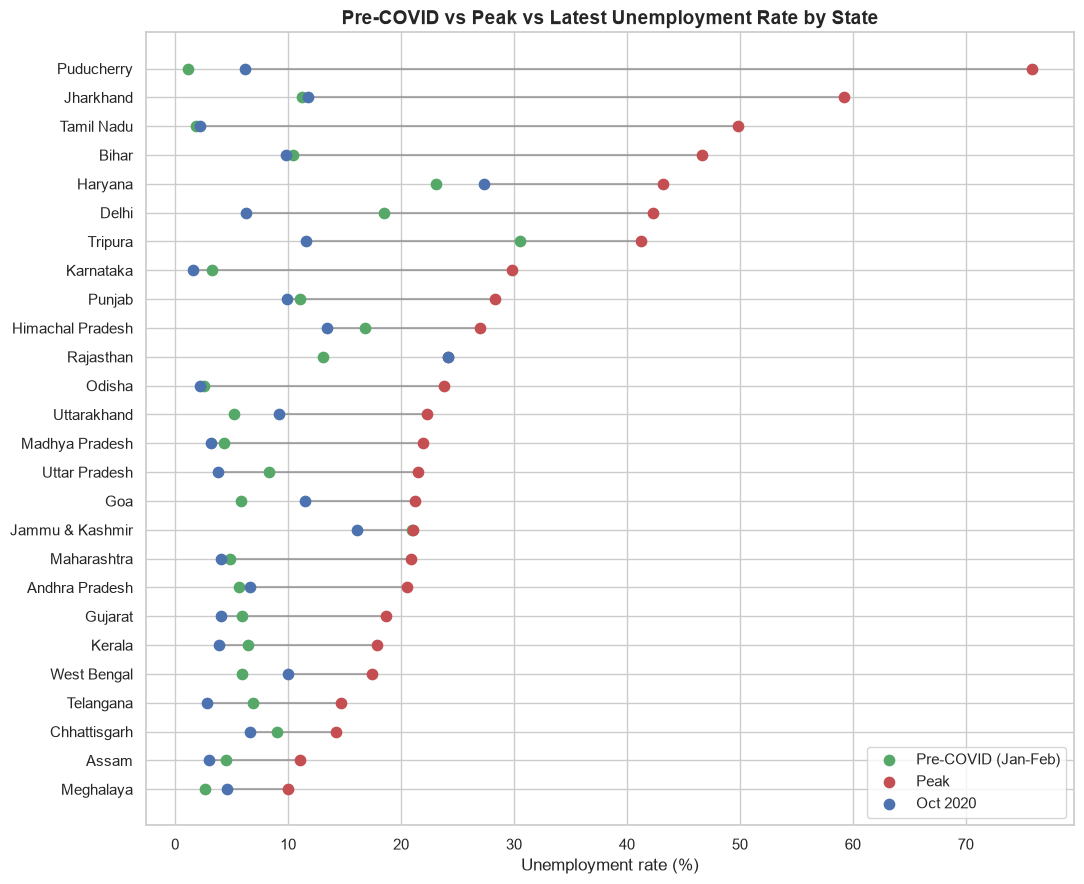

In [27]:
rec_plot = rec.sort_values("Peak", ascending=True)
y = np.arange(len(rec_plot))
plt.figure(figsize=(11, 9))
plt.hlines(y, rec_plot["Oct_2020"], rec_plot["Peak"], color="grey", alpha=0.6)
plt.scatter(rec_plot["Pre_COVID"], y, color="#55A868", s=55, label="Pre-COVID (Jan-Feb)", zorder=3)
plt.scatter(rec_plot["Peak"], y, color="#C44E52", s=55, label="Peak", zorder=3)
plt.scatter(rec_plot["Oct_2020"], y, color="#4C72B0", s=55, label="Oct 2020", zorder=3)
plt.yticks(y, rec_plot.index)
plt.title("Pre-COVID vs Peak vs Latest Unemployment Rate by State")
plt.xlabel("Unemployment rate (%)")
plt.legend()
plt.tight_layout()
save_fig("14_state_recovery")
plt.show()

### B4. Impact on jobs: change in the estimated employed (Feb to Apr 2020)

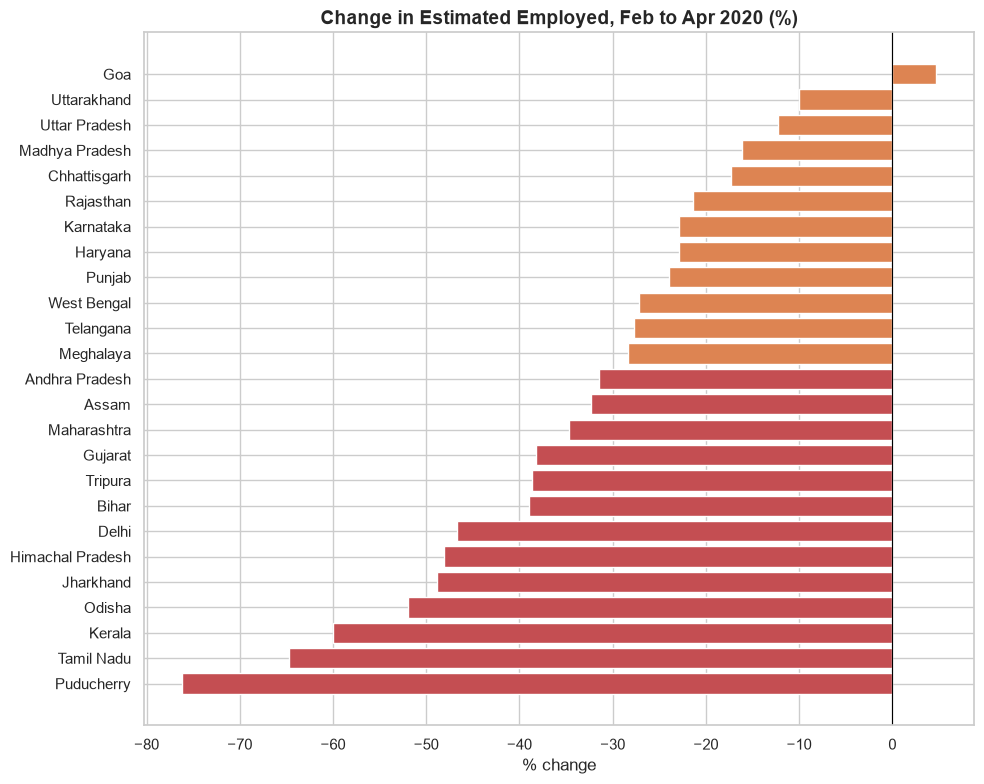

Median state change in employed: -31.5 %
Worst 5 states:
Region
Puducherry   -76.2
Tamil Nadu   -64.7
Kerala       -60.0
Odisha       -51.9
Jharkhand    -48.8
dtype: float64


In [28]:
emp = df2.pivot_table(index="Region", columns="Date", values="Employed")
feb = emp[pd.Timestamp("2020-02-29")]
apr = emp[pd.Timestamp("2020-04-30")]
emp_change = ((apr - feb) / feb * 100).dropna().sort_values()

plt.figure(figsize=(10, 8))
colors = ["#C44E52" if v < -30 else "#DD8452" for v in emp_change]
plt.barh(emp_change.index, emp_change.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Change in Estimated Employed, Feb to Apr 2020 (%)")
plt.xlabel("% change")
plt.tight_layout()
save_fig("15_employed_change")
plt.show()

print("Median state change in employed:", round(emp_change.median(), 1), "%")
print("Worst 5 states:")
print(emp_change.head(5).round(1))

### B5. Geographic view (using the corrected latitude and longitude)

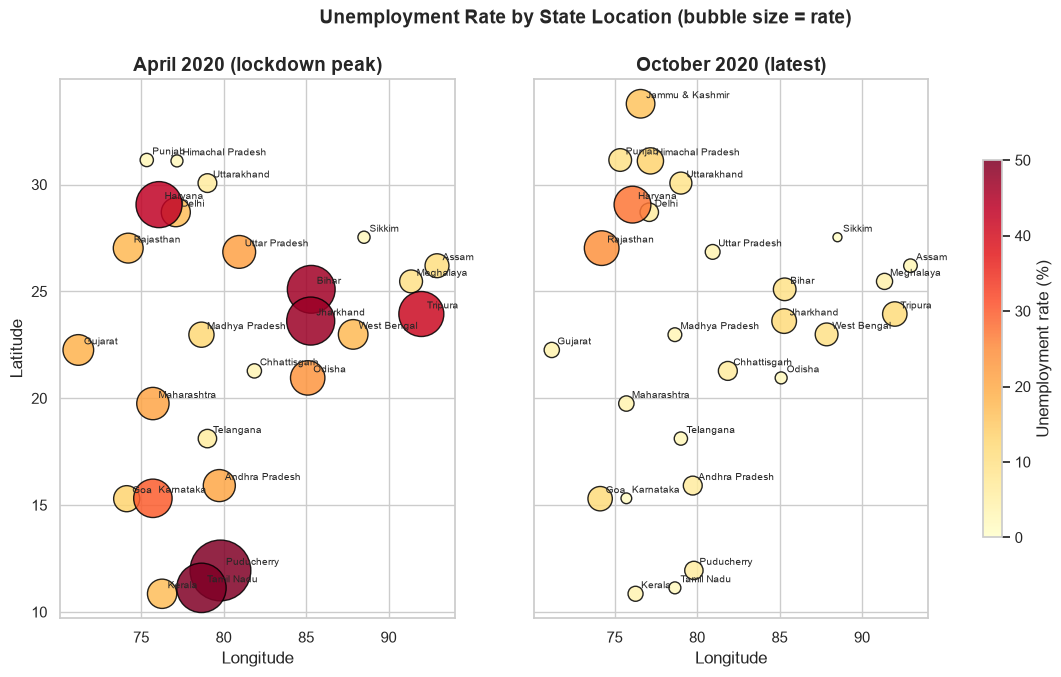

In [29]:
loc = df2.drop_duplicates("Region").set_index("Region")[["Latitude", "Longitude"]]
apr_rate = piv[pd.Timestamp("2020-04-30")].dropna()
oct_rate = piv.iloc[:, -1].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)
for ax, series, title in zip(axes, [apr_rate, oct_rate], ["April 2020 (lockdown peak)", "October 2020 (latest)"]):
    pts = loc.loc[series.index]
    sc = ax.scatter(pts["Longitude"], pts["Latitude"], s=series.values * 25 + 20, c=series.values,
                    cmap="YlOrRd", vmin=0, vmax=50, edgecolor="black", alpha=0.85)
    for name, row in pts.iterrows():
        ax.annotate(name, (row["Longitude"], row["Latitude"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
    ax.set_title(title)
    ax.set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
fig.colorbar(sc, ax=axes, label="Unemployment rate (%)", shrink=0.7)
plt.suptitle("Unemployment Rate by State Location (bubble size = rate)", fontweight="bold", fontsize=14)
save_fig("16_geo_bubble")
plt.show()

---
# PART C: Bonus. Clustering States by Unemployment Behaviour
We group states into clusters that behaved similarly, using four features: pre-COVID rate, peak rate, October 2020 rate and average labour participation. This is **unsupervised learning (KMeans)**, so no labels are needed.

In [30]:
feat = rec[["Pre_COVID", "Peak", "Oct_2020"]].copy()
feat["Avg_LPR"] = df2.groupby("Region")["Labour_Participation_Rate"].mean()
feat = feat.dropna()

X = StandardScaler().fit_transform(feat)

scores = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    scores[k] = silhouette_score(X, km.labels_)
print("Silhouette score by k:", {k: round(v, 3) for k, v in scores.items()})

# Scores are close (0.36 - 0.42). k=5 scores highest but creates a one-state cluster (Tripura),
# which is not useful for grouping. We use k=4 for interpretability.
best_k = 4
print("Chosen k:", best_k)

Silhouette score by k: {2: 0.358, 3: 0.382, 4: 0.397, 5: 0.42, 6: 0.408}
Chosen k: 4


In [31]:
km = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(X)
feat["Cluster"] = km.labels_

profile = feat.groupby("Cluster").mean().round(2)
profile["States"] = feat.groupby("Cluster").size()
display(profile)

for c in sorted(feat["Cluster"].unique()):
    print(f"Cluster {c}: {', '.join(feat.index[feat['Cluster'] == c])}")

,Pre_COVID,Peak,Oct_2020,Avg_LPR,States
Cluster,,,,,
0,5.92,20.69,5.68,39.99,14
1,20.49,33.15,16.48,42.42,6
2,4.76,12.36,3.73,57.42,2
3,6.17,57.89,7.49,37.71,4


Cluster 0: Uttar Pradesh, Kerala, Chhattisgarh, Gujarat, Karnataka, Assam, Madhya Pradesh, Punjab, Maharashtra, Odisha, Andhra Pradesh, Uttarakhand, West Bengal, Goa
Cluster 1: Tripura, Delhi, Jammu & Kashmir, Himachal Pradesh, Haryana, Rajasthan
Cluster 2: Telangana, Meghalaya
Cluster 3: Bihar, Tamil Nadu, Jharkhand, Puducherry


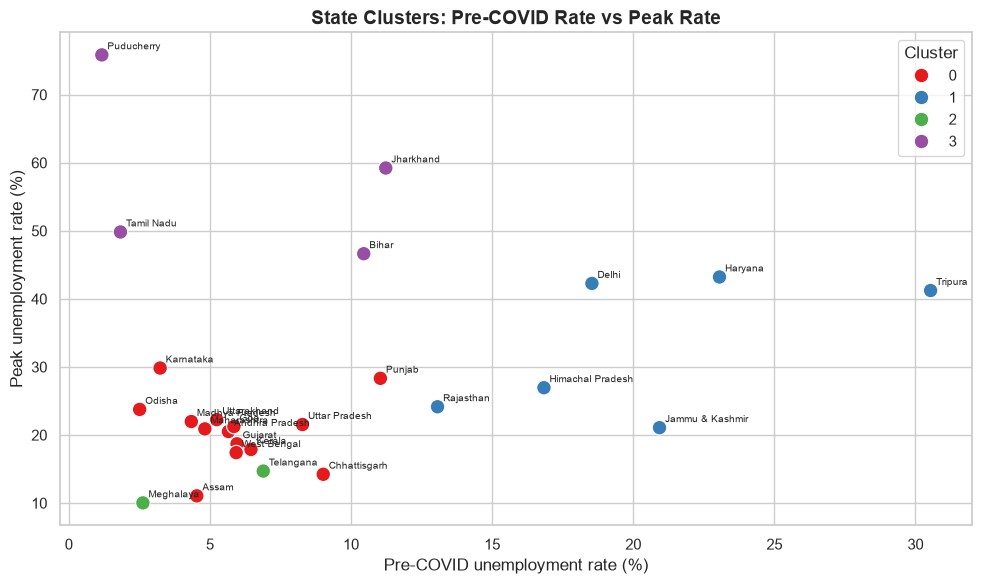

In [32]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=feat, x="Pre_COVID", y="Peak", hue="Cluster", palette="Set1", s=110)
for name, row in feat.iterrows():
    plt.annotate(name, (row["Pre_COVID"], row["Peak"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
plt.title("State Clusters: Pre-COVID Rate vs Peak Rate")
plt.xlabel("Pre-COVID unemployment rate (%)")
plt.ylabel("Peak unemployment rate (%)")
plt.tight_layout()
save_fig("17_state_clusters")
plt.show()

---
# PART D: Key Metrics Summary

In [33]:
summary = {
    "Pre-COVID average rate, dataset 1 (May 2019 - Feb 2020)": f"{nat[nat.index < '2020-03-01'].mean():.2f}%",
    "Peak average rate, dataset 1": f"{nat.max():.2f}% ({nat.idxmax().strftime('%b %Y')})",
    "Peak average rate, dataset 2": f"{nat2.max():.2f}% ({nat2.idxmax().strftime('%b %Y')})",
    "Latest average rate (Oct 2020)": f"{nat2.iloc[-1]:.2f}%",
    "Highest single state-month rate": f"{df1['Unemployment_Rate'].max():.2f}% ({df1.loc[df1['Unemployment_Rate'].idxmax(), 'Region']})",
    "Rural average (dataset 1)": f"{rural.mean():.2f}%",
    "Urban average (dataset 1)": f"{urban.mean():.2f}%",
    "State with highest average rate": f"{state_avg.index[0]} ({state_avg.iloc[0]:.2f}%)",
    "State with lowest average rate": f"{state_avg.index[-1]} ({state_avg.iloc[-1]:.2f}%)",
}
pd.Series(summary, name="Value").to_frame()

,Value
"Pre-COVID average rate, dataset 1 (May 2019 - Feb 2020)",9.51%
"Peak average rate, dataset 1",24.88% (May 2020)
"Peak average rate, dataset 2",23.24% (May 2020)
Latest average rate (Oct 2020),8.03%
Highest single state-month rate,76.74% (Puducherry)
Rural average (dataset 1),10.32%
Urban average (dataset 1),13.17%
State with highest average rate,Tripura (28.35%)
State with lowest average rate,Meghalaya (4.80%)


---
# 10. Key Insights

> All numbers below come from the outputs above. Averages are simple averages across states (not population-weighted), so they describe the typical state, not the national rate.

**1. COVID-19 caused a sharp but temporary shock.**
The average state unemployment rate sat near 9 to 10% from May 2019 to Feb 2020, rose slightly to 10.7% in March 2020, then jumped to **23.6% in April and 24.9% in May 2020** (dataset 1). In June 2020 it fell back to about 11.9%. Dataset 2 shows the same shape (peak 23.2% in May) and continues the recovery to **8.0% by October 2020**, which is below the Jan to Feb 2020 level of 9.2%.

**2. Urban areas were hit harder than rural areas.**
Over the whole period urban unemployment averaged 13.2% versus 10.3% in rural areas, and the difference is statistically significant (Welch t-test p = 0.0003; Mann-Whitney p < 0.001). During the lockdown urban reached 21.6% versus 17.7% rural. By June 2020 the two were almost equal (about 12%).

**3. The shock was very uneven across states.**
Average unemployment in the lockdown months rose most in Puducherry (+44 pp), Jharkhand (+27 pp), Tamil Nadu (+27 pp) and Bihar (+23 pp). The single highest records were Puducherry urban at 76.7% (Apr 2020) and Jharkhand urban at 70.2% (May 2020).

**4. East and South zones took the biggest hit; North and Northeast were hit least but started higher.**
Between Pre-COVID and Lockdown the East zone rose by 18.5 pp and the South by 17.6 pp, while the West rose 5.8 pp, North 4.0 pp and Northeast 2.9 pp. The North zone already had the highest pre-COVID rate (14.6%). The zone differences are significant (Kruskal-Wallis p < 0.001).

**5. Some states have a structural problem that predates COVID.**
Haryana (about 23%), Tripura (about 31% in Jan to Feb) and Delhi (about 19%) were already high before the lockdown. These are not just lockdown effects, so they need long-term job creation, not only recovery support.

**6. Recovery is not uniform.**
Most states came back near or below their pre-COVID rate by October 2020, but a few are still above it: Rajasthan (+11 pp, and October was its peak month), Goa, Puducherry, Haryana, West Bengal and Uttarakhand.

**7. Employment loss was large.**
Between Feb and Apr 2020 the median state lost about **31.5%** of its estimated employed (Puducherry -76%, Tamil Nadu -65%, Kerala -60%, Odisha -52%, Jharkhand -49%).

**8. Labour participation and unemployment are unrelated here.**
The correlation is r = 0.003 (p = 0.94), so a high unemployment rate does not simply mean people left the labour force. The shock hit those who were actively looking for work.

**9. Clustering found four behaviour groups** (Section Part C): a large group of states with moderate shock and full recovery, a group with chronic high unemployment (e.g. Haryana, Rajasthan, Himachal Pradesh), a group with extreme lockdown spikes (Bihar, Tamil Nadu, Jharkhand, Puducherry), and a small group with high participation and low unemployment (Telangana, Meghalaya).

# 11. Policy Recommendations

1. **Targeted urban employment support for future shocks.** Urban workers (daily wage, services, informal sector) lost work fastest, so urban employment guarantee or wage-support schemes would give the quickest relief.
2. **Keep rural job guarantee schemes funded and ready.** Rural unemployment also doubled in the lockdown; rural employment guarantee programmes act as a safety net when migrant workers return home.
3. **Prioritise the worst-hit states.** Puducherry, Jharkhand, Tamil Nadu, Bihar and Delhi need state-specific relief and faster restart of industry and construction.
4. **Address chronic unemployment separately.** Haryana, Tripura, Rajasthan, Himachal Pradesh and Jammu & Kashmir had high unemployment before COVID, which points to a skills and job-creation gap rather than a temporary shock.
5. **Improve data collection.** Publish unemployment by age group, gender, education and industry so that policy can be targeted. The datasets used here cannot answer those questions.
6. **Build an early-warning dashboard.** Monthly state-level tracking (like this analysis) would let governments spot a spike within weeks.

# 12. Limitations
- The data has **no age, gender, education or industry columns**, so those breakdowns from the task slide cannot be done.
- Averages are **unweighted across states**: a small state counts as much as a large one.
- Some state-months are missing (for example, not every state has both a rural and an urban record every month), so a few comparisons use slightly different numbers of states.
- Dataset 1 and dataset 2 overlap in Jan to Jun 2020 but are **separate sources** and are not merged; small differences between them are expected.
- This is a descriptive analysis. It shows patterns and associations; it does not prove causes.

# 13. Conclusion
Unemployment in India followed a stable pattern until early 2020, spiked sharply during the COVID-19 lockdown (to roughly 24% on average), and then recovered quickly once restrictions were eased, reaching about 8% by October 2020. The shock was strongest in urban areas and in the East and South zones, and some states carry a high unemployment level that was there before the pandemic. Policy should combine short-term relief for shock-hit states with long-term job creation in chronically high-unemployment states.